# RecruitGen — Model 4 of 4: GAN (Synthetic Candidate Profiles for Dataset Augmentation)

**Goal:** generate realistic synthetic candidate profiles — the 9 RecruitGen features plus a job role — to augment
training data and to test the pipeline, and measure honestly whether that augmentation helps.

```
noise z + job role ─► Generator ─► 9 features ─► Critic (WGAN-GP) ◄─ real Kaggle profiles + job role
```

* **Model:** conditional WGAN-GP (Wasserstein loss + gradient penalty), PyTorch
* **Profile:** experience · projects · programming · analytics · ML/AI · cloud · communication · certifications · education · job role
* **Evaluation:** GAN quality & diversity (separately) · downstream job-role classifier: real only vs GAN-augmented on the
  **same untouched real test split** (accuracy, precision, recall, F1, classification report, confusion matrix) ·
  comparison with a CVAE baseline and random oversampling

**Outputs:** `generator.safetensors`, `discriminator.safetensors`, `config.json`, `metrics.json` (shown in the app's
*GAN Candidate Generator* page). All code lives in `models/gan/*.py`; this notebook runs it step by step.

## 1. Dataset — Kaggle Resume Dataset

**Link:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

| File | Content |
|---|---|
| `Resume/Resume.csv` | `ID`, `Resume_str` (plain text), `Resume_html`, `Category` — 2,484 resumes, 24 categories |
| `data/data/<CATEGORY>/<ID>.pdf` | the same resumes as PDF files (not needed for the GAN) |

**Setup — pick one:**

1. **Automatic** (default): the next cells call `kagglehub.dataset_download("snehaanbhawal/resume-dataset")`.
   The dataset is public; if Kaggle asks for authentication, put your API token in `~/.kaggle/kaggle.json`
   (Kaggle → Settings → API → *Create New Token*).
2. **Manual:** download the ZIP from the link above and extract it to `RecruitGen/data/kaggle_resume/`
   so that `RecruitGen/data/kaggle_resume/Resume/Resume.csv` exists.
3. **Kaggle CLI:** `kaggle datasets download -d snehaanbhawal/resume-dataset -p data/kaggle_resume --unzip`

You can also point `DATA_PATH` below (or the `RECRUITGEN_KAGGLE_DIR` environment variable) at any folder containing `Resume.csv`.

> **Important:** the dataset contains raw resume text and a category only — **not** the 9 RecruitGen features.
> They are extracted below with the app's own `feature_extractor.py`. The 24 Kaggle categories (HR, Chef,
> Information Technology, …) are used as the job-role condition; they are *not* the 5 roles of Transformer V3 / CVAE.

## 2. Setup

In [1]:
import os, sys, json, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the RecruitGen project importable (this notebook lives in RecruitGen/models/gan/)
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from models.gan import dataset as ds
from models.gan.gan import Generator, Critic, CandidateGAN, save_checkpoint, MODEL_DIR
from models.gan.training import train_gan
from models.gan.train import verify_checkpoint, evaluate, build_metrics, write_metrics
from models.gan.evaluation import unit

SEED = 42
QUICK_RUN = False                 # True = fast end-to-end test (300 iterations, 2 seeds)
ITERATIONS = 300 if QUICK_RUN else 6000
EVAL_SEEDS = (0, 1) if QUICK_RUN else (0, 1, 2, 3, 4)
CVAE_EPOCHS = 20 if QUICK_RUN else 150

DATA_PATH = None                  # None = data/kaggle_resume/, $RECRUITGEN_KAGGLE_DIR or the kagglehub cache
OUTPUT_DIR = "outputs"
EXPORT_TO_APP = True              # copy the trained files into models/gan/ so the Streamlit app uses them
os.makedirs(OUTPUT_DIR, exist_ok=True)
start = time.time()

## 3. Load and inspect the raw dataset

In [2]:
csv_path = ds.find_resume_csv(DATA_PATH) or ds.download_dataset()
raw = ds.load_raw(csv_path)
print("File:", csv_path)
print("Shape:", raw.shape, "| columns:", list(raw.columns))
print("Missing values:", raw.isna().sum().to_dict())
print("Duplicate resume texts:", int(raw["Resume_str"].duplicated().sum()))
raw["Category"].value_counts()

File: C:\Users\admin1\.cache\kagglehub\datasets\snehaanbhawal\resume-dataset\versions\1\Resume\Resume.csv
Shape: (2484, 4) | columns: ['ID', 'Resume_str', 'Resume_html', 'Category']
Missing values: {'ID': 0, 'Resume_str': 0, 'Resume_html': 0, 'Category': 0}
Duplicate resume texts: 2


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

In [3]:
print(raw.loc[0, "Resume_str"][:1200])
raw["Resume_str"].str.len().describe().round(0)

         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss preve

count     2484.0
mean      6295.0
std       2769.0
min         21.0
25%       5160.0
50%       5886.0
75%       7227.0
max      38842.0
Name: Resume_str, dtype: float64

## 4. Preprocessing — resume text → 9 features

1. drop resumes too short for the extractor and exact duplicate texts
2. extract the 9 features with `models/transformer_v3/feature_extractor.py` (the extractor the app uses)
3. clip to the app's input ranges — the extractor occasionally reads phrases such as "500 certificates" as a count
4. stratified **train / validation / test** split (70 / 15 / 15). The GAN and the CVAE baseline are trained on train,
   tuned on validation; **test is only used for the final report**.

In [4]:
table, report = ds.build_feature_table(raw)
table = ds.split_table(table, seed=SEED)
report["source_file"] = os.path.basename(csv_path)
report["split_sizes"] = {k: int(v) for k, v in table["split"].value_counts().items()}
ds.save_processed(table)          # data/gan/kaggle_features.csv — used by the app's augmentation tab
print(json.dumps({k: v for k, v in report.items() if k != "role_counts"}, indent=2))
table[ds.FEATURE_NAMES].describe().round(2).T

{
  "raw_rows": 2484,
  "raw_categories": 24,
  "dropped_too_short": 1,
  "dropped_duplicate_text": 2,
  "clipped_values": {
    "experience_years": 48,
    "projects_count": 50,
    "certification_count": 120
  },
  "rows": 2481,
  "source_file": "Resume.csv",
  "split_sizes": {
    "train": 1736,
    "test": 373,
    "val": 372
  }
}


,count,mean,std,min,25%,50%,75%,max
experience_years,2481.0,1.82,4.87,0.0,0.0,0.0,0.0,20.0
projects_count,2481.0,0.92,2.86,0.0,0.0,0.0,1.0,20.0
programming_score,2481.0,7.88,17.28,0.0,0.0,0.0,15.0,100.0
data_analytics_score,2481.0,18.40,15.71,0.0,15.0,15.0,30.0,100.0
ml_ai_score,2481.0,25.58,11.23,0.0,15.0,30.0,30.0,100.0
cloud_score,2481.0,13.15,10.21,0.0,0.0,15.0,15.0,100.0
communication_score,2481.0,55.30,13.26,40.0,50.0,50.0,60.0,100.0
certification_count,2481.0,0.90,3.39,0.0,0.0,0.0,0.0,15.0
education_level,2481.0,2.13,0.86,1.0,1.0,2.0,3.0,5.0


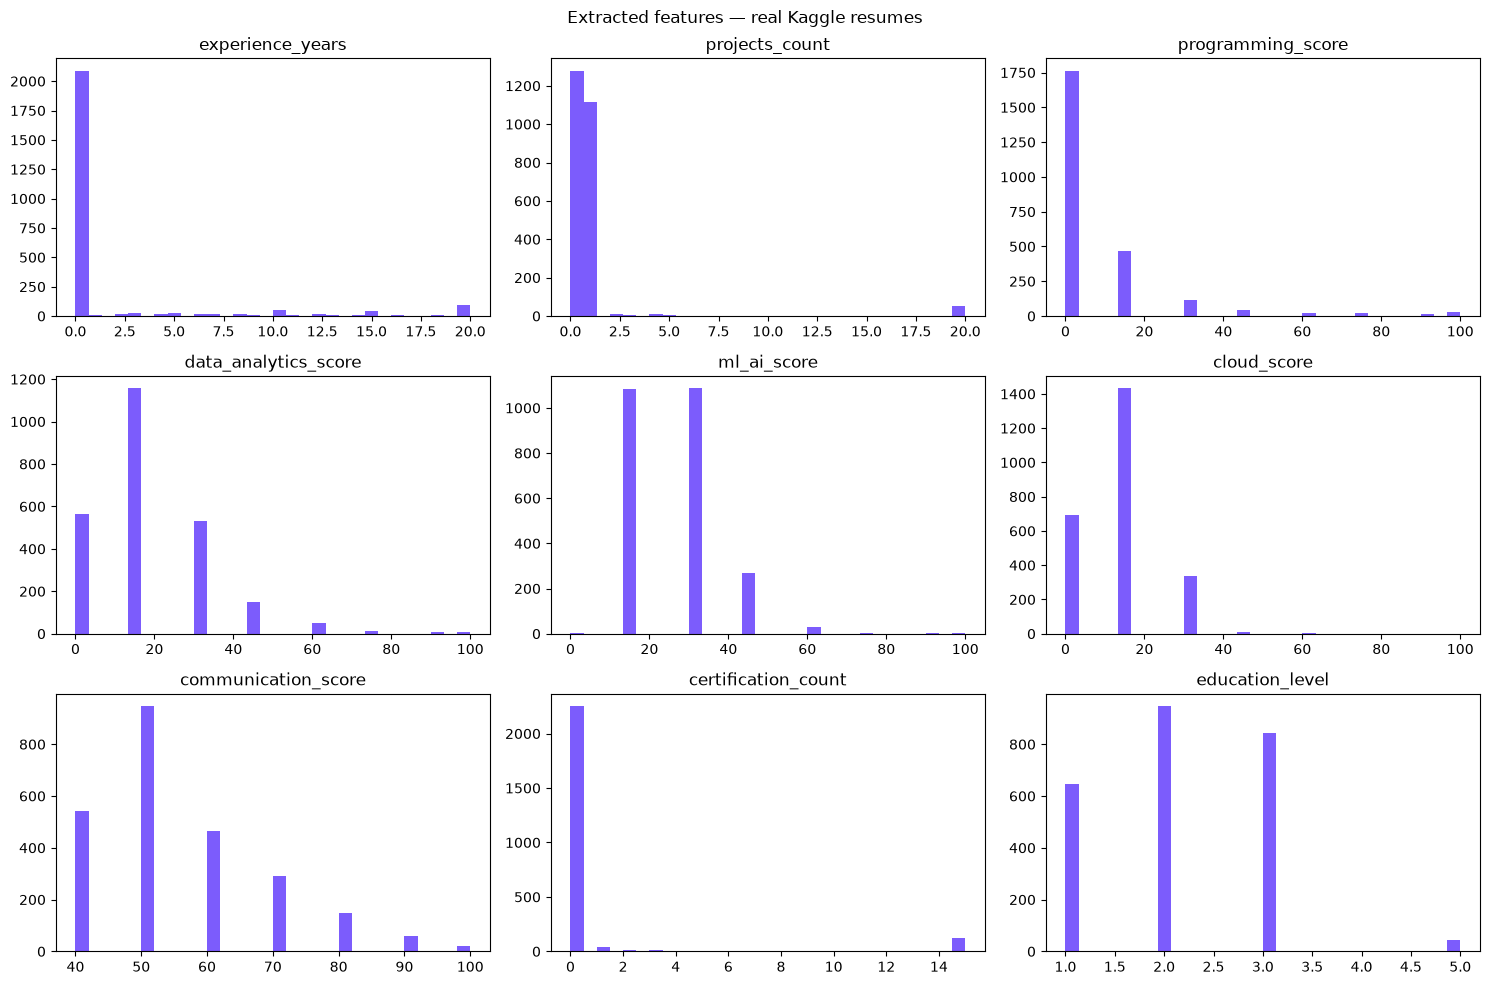

{'train': 1736, 'val': 372, 'test': 373} | 24 job roles


,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
job_role,,,,,,,,,
Accountant,1.9,0.7,1.8,25.9,23.8,14.5,51.0,0.4,2.3
Advocate,2.0,0.5,3.8,15.6,25.3,15.3,57.9,1.0,2.0
Agriculture,2.1,1.2,8.0,20.5,25.7,14.0,55.7,0.7,2.5
Apparel,1.0,0.6,3.4,15.7,24.6,12.2,54.9,1.2,1.8
Arts,1.6,0.4,5.1,13.1,23.3,11.5,56.2,1.0,2.3
Automobile,2.8,0.8,7.1,24.4,27.5,14.2,54.7,1.3,2.0
Aviation,1.9,0.9,7.0,15.4,23.7,13.6,51.6,1.4,2.0
BPO,2.3,0.6,8.6,28.6,26.6,9.5,53.6,1.5,2.1
Banking,1.5,0.6,6.3,21.1,27.4,11.7,55.4,0.8,2.1


In [5]:
fig, ax = plt.subplots(3, 3, figsize=(15, 10))
for a, f in zip(ax.flat, ds.FEATURE_NAMES):
    a.hist(table[f], bins=30, color="#7C5CFC"); a.set_title(f)
plt.suptitle("Extracted features — real Kaggle resumes"); plt.tight_layout(); plt.show()

train, val, test = (table[table["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
role_names = sorted(table["job_role"].unique())
print({k: len(v) for k, v in [("train", train), ("val", val), ("test", test)]}, "|", len(role_names), "job roles")
table.groupby("job_role")[ds.FEATURE_NAMES].mean().round(1)

## 5. Model — conditional WGAN-GP

* **Generator:** `[z (32) ‖ role one-hot]` → 128 → 256 → 128 → 9 (`tanh`, features scaled to [-1, 1] with fixed bounds)
* **Critic:** `[features ‖ role one-hot]` → 256 → 128 → 1 (no sigmoid, no batch norm)
* **Loss:** critic `D(fake) − D(real) + 10·GP`, generator `−D(fake)`; 5 critic steps per generator step, Adam (0.5, 0.9)
* **Post-processing:** generated values are mapped back to real units and snapped to the nearest value observed in
  the training data, because the extractor only produces discrete values (scores in steps of 15, counts, levels).

In [6]:
print(Generator(len(ds.FEATURE_NAMES), len(role_names)))
print(Critic(len(ds.FEATURE_NAMES), len(role_names)))

Generator(
  (net): Sequential(
    (0): Linear(in_features=56, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=128, out_features=9, bias=True)
    (7): Tanh()
  )
)
Critic(
  (net): Sequential(
    (0): Linear(in_features=33, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


## 6. Training (checkpoint selected on the validation split)

In [7]:
model, critic, history, config = train_gan(train, val, role_names, iterations=ITERATIONS, seed=SEED,
                                           eval_every=50 if QUICK_RUN else 100, log_every=500,
                                           dataset_report=report)
print("Best iteration:", config["training"]["best_iteration"], "| validation distance:",
      round(config["training"]["best_val_distance"], 4), "|", config["training"]["seconds"], "s")

iter   500 | critic  -0.2870 | generator   1.0462 | W-est  0.3561 | val dist 0.0537 (best 0.0537 @ 500)


iter  1000 | critic  -0.1400 | generator  -0.1583 | W-est  0.2360 | val dist 0.0660 (best 0.0475 @ 800)


iter  1500 | critic  -0.0347 | generator   0.8402 | W-est  0.1047 | val dist 0.0516 (best 0.0462 @ 1400)


iter  2000 | critic  -0.1969 | generator   1.5522 | W-est  0.2552 | val dist 0.0624 (best 0.0398 @ 1700)


iter  2500 | critic  -0.0629 | generator  -0.4962 | W-est  0.0975 | val dist 0.0409 (best 0.0398 @ 1700)


iter  3000 | critic  -0.0684 | generator  -0.5464 | W-est  0.1028 | val dist 0.0662 (best 0.0398 @ 1700)


... (2 outputs left out)

iter  4500 | critic  -0.0591 | generator   0.1674 | W-est  0.1001 | val dist 0.0328 (best 0.0269 @ 4300)


iter  5000 | critic  -0.0988 | generator   0.6298 | W-est  0.1360 | val dist 0.0382 (best 0.0269 @ 4300)


iter  5500 | critic   0.0468 | generator   0.8862 | W-est  0.0273 | val dist 0.0336 (best 0.0269 @ 4300)


iter  6000 | critic   0.0830 | generator  -1.0145 | W-est -0.0543 | val dist 0.0327 (best 0.0269 @ 4300)
Best iteration: 4300 | validation distance: 0.0269 | 122.7 s


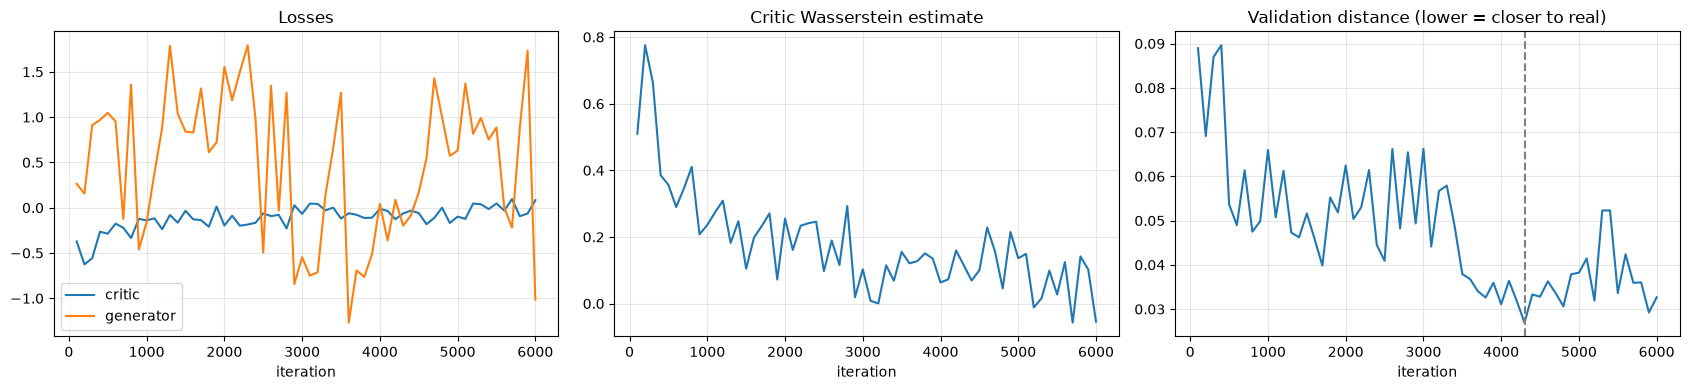

In [8]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(h["iteration"], h["critic_loss"], label="critic"); ax[0].plot(h["iteration"], h["generator_loss"], label="generator")
ax[0].set_title("Losses"); ax[0].legend()
ax[1].plot(h["iteration"], h["wasserstein_estimate"]); ax[1].set_title("Critic Wasserstein estimate")
ax[2].plot(h["iteration"], h["val_distance"]); ax[2].axvline(config["training"]["best_iteration"], ls="--", c="grey")
ax[2].set_title("Validation distance (lower = closer to real)")
for a in ax: a.set_xlabel("iteration"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Generate synthetic profiles (clearly labelled as synthetic)

In [9]:
sample = pd.DataFrame(model.generate("Information Technology", 10, seed=SEED))
sample.insert(0, "data_source", "SYNTHETIC (GAN)")
sample

,data_source,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level,job_role
0,SYNTHETIC (GAN),0.2,0,0.0,60.0,30.0,15.0,50.0,14,3,Information Technology
1,SYNTHETIC (GAN),0.0,0,75.0,60.0,45.0,15.0,50.0,0,2,Information Technology
2,SYNTHETIC (GAN),1.0,1,15.0,15.0,30.0,15.0,60.0,0,1,Information Technology
3,SYNTHETIC (GAN),0.0,3,75.0,45.0,30.0,15.0,60.0,0,2,Information Technology
4,SYNTHETIC (GAN),0.8,0,0.0,30.0,30.0,30.0,60.0,9,2,Information Technology
5,SYNTHETIC (GAN),0.0,0,60.0,45.0,45.0,15.0,60.0,0,1,Information Technology
6,SYNTHETIC (GAN),0.0,0,0.0,30.0,45.0,15.0,70.0,0,1,Information Technology
7,SYNTHETIC (GAN),0.0,0,0.0,30.0,15.0,15.0,40.0,0,2,Information Technology
8,SYNTHETIC (GAN),8.0,0,100.0,30.0,30.0,15.0,60.0,0,2,Information Technology
9,SYNTHETIC (GAN),0.0,0,15.0,30.0,30.0,15.0,60.0,0,3,Information Technology


## 8. Save the checkpoint and test reloading it

In [10]:
save_checkpoint(model.generator, critic, config, OUTPUT_DIR)
check = verify_checkpoint(model, OUTPUT_DIR)
print(check)
assert check["identical_samples"], "Reloaded generator does not reproduce the trained one"
print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

{'reloaded': True, 'identical_samples': True, 'params': 74377}
Saved: ['config.json', 'discriminator.safetensors', 'generator.safetensors']


## 9. Evaluation

* **Quality / diversity** of each generator against the held-out real test split, next to a *real reference*
  (real training rows scored the same way = what a perfect generator would reach).
* **Downstream job-role classifier** (Random Forest, 9 features): real only vs real + GAN vs real + CVAE baseline vs
  real + random oversampling. Four augmentation strategies; the one with the best **validation** macro-F1 is reported
  on the **test** split, averaged over several seeds.
* **TSTR:** train on synthetic only, test on real.
* **CVAE baseline:** same layer sizes as `models/cvae/` but retrained on this split (the shipped CVAE is conditioned
  on 5 different roles and is left unchanged).

In [11]:
results = evaluate(model, train, val, test, role_names, EVAL_SEEDS, cvae_epochs=CVAE_EPOCHS)

Training the CVAE baseline (same layer sizes as models/cvae) on the same split ...


CVAE baseline: best val loss 0.2354 after 65 epochs
Quality & diversity against the held-out test split ...


Downstream job-role classifier: real only vs augmented (same untouched test split) ...


real only            | test macro-F1 0.0865


GAN                  | chosen balance    | test macro-F1 0.0807 (Δ -0.0058 ± 0.0078, improved on 2/5 seeds)


CVAE baseline        | chosen balance    | test macro-F1 0.0795 (Δ -0.0070 ± 0.0065, improved on 1/5 seeds)


Random oversampling  | chosen ratio_2.0  | test macro-F1 0.0813 (Δ -0.0052 ± 0.0139, improved on 2/5 seeds)


TSTR (train on synthetic only, test on real) ...


In [12]:
quality = pd.DataFrame([{
    "generator": name,
    "mean KS": q["quality"]["mean_ks_statistic"], "mean Wasserstein (0-1)": q["quality"]["mean_wasserstein_0_1"],
    "correlation gap": q["quality"]["correlation_gap"], "per-role mean gap": q["quality"]["per_role_mean_gap_0_1"],
    "C2ST AUC": q["quality"]["c2st_auc"], "unique rows": q["diversity"]["unique_row_ratio"],
    "exact train copies": q["diversity"]["exact_train_copy_rate"], "DCR median": q["diversity"]["dcr_median"],
    "pairwise distance": q["diversity"]["mean_pairwise_distance"],
} for name, q in results["quality"].items()]).set_index("generator")
quality.round(4)

,mean KS,mean Wasserstein (0-1),correlation gap,per-role mean gap,C2ST AUC,unique rows,exact train copies,DCR median,pairwise distance
generator,,,,,,,,,
Real reference,0.0343,0.0180,0.0506,0.0510,0.4777,0.8257,0.4772,0.0500,0.5964
GAN,0.1415,0.0365,0.0941,0.0572,0.8624,0.8123,0.3673,0.1000,0.7125
CVAE baseline,0.4138,0.0795,0.1403,0.0450,0.9999,0.1448,0.0000,0.1202,0.1602


In [13]:
aug = results["augmentation"]
rows = [{"training data": "real only", "strategy": "-", **{k: f"{v['mean']:.4f} ± {v['std']:.4f}" for k, v in aug["real_only"]["test"].items()}}]
for name, s in aug["samplers"].items():
    c = s["strategies"][s["chosen_strategy"]]
    rows.append({"training data": f"real + {name}", "strategy": c["label"],
                 **{k: f"{v['mean']:.4f} ± {v['std']:.4f}" for k, v in c["test"].items()},
                 "Δ macro-F1": f"{s['test_f1_macro_delta_vs_real']['mean']:+.4f}",
                 "seeds improved": f"{s['test_f1_macro_delta_vs_real']['seeds_improved']}/{s['test_f1_macro_delta_vs_real']['seeds']}"})
print("Test split (untouched, real resumes only):")
pd.DataFrame(rows).set_index("training data")

Test split (untouched, real resumes only):


,strategy,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,Δ macro-F1,seeds improved
training data,,,,,,,,
real only,-,0.0895 ± 0.0065,0.0911 ± 0.0076,0.0854 ± 0.0059,0.0865 ± 0.0064,0.0902 ± 0.0069,NaN,NaN
real + GAN,Balance every role to the largest,0.0815 ± 0.0021,0.0851 ± 0.0030,0.0819 ± 0.0083,0.0807 ± 0.0041,0.0828 ± 0.0011,-0.0058,2/5
real + CVAE baseline,Balance every role to the largest,0.0810 ± 0.0069,0.0859 ± 0.0076,0.0772 ± 0.0062,0.0795 ± 0.0068,0.0830 ± 0.0074,-0.0070,1/5
real + Random oversampling,+200% synthetic per role,0.0847 ± 0.0095,0.0860 ± 0.0072,0.0804 ± 0.0088,0.0813 ± 0.0077,0.0853 ± 0.0085,-0.0052,2/5


In [14]:
pd.DataFrame([{"sampler": n, "strategy": st["label"], "synthetic rows": st["synthetic_rows"],
               "val macro-F1": round(st["val"]["f1_macro"]["mean"], 4), "test macro-F1": round(st["test"]["f1_macro"]["mean"], 4),
               "chosen": k == s["chosen_strategy"]}
              for n, s in aug["samplers"].items() for k, st in s["strategies"].items()])

,sampler,strategy,synthetic rows,val macro-F1,test macro-F1,chosen
0,GAN,+50% synthetic per role,866,0.0829,0.0867,False
1,GAN,+100% synthetic per role,1736,0.0898,0.0871,False
2,GAN,+200% synthetic per role,3472,0.0936,0.0837,False
3,GAN,Balance every role to the largest,280,0.1008,0.0807,True
4,CVAE baseline,+50% synthetic per role,866,0.0838,0.0836,False
5,CVAE baseline,+100% synthetic per role,1736,0.0831,0.0767,False
6,CVAE baseline,+200% synthetic per role,3472,0.0858,0.0765,False
7,CVAE baseline,Balance every role to the largest,280,0.0996,0.0795,True
8,Random oversampling,+50% synthetic per role,866,0.0956,0.0706,False
9,Random oversampling,+100% synthetic per role,1736,0.0921,0.0773,False


===== real_only (test split, seed 0) =====
                        precision    recall  f1-score   support

            Accountant     0.1111    0.1111    0.1111        18
              Advocate     0.0385    0.0556    0.0455        18
           Agriculture     0.2500    0.2222    0.2353         9
               Apparel     0.0667    0.0667    0.0667        15
                  Arts     0.0000    0.0000    0.0000        16
            Automobile     0.0000    0.0000    0.0000         5
              Aviation     0.1765    0.1765    0.1765        17
                   BPO     0.0000    0.0000    0.0000         3
               Banking     0.0588    0.0588    0.0588        17
  Business Development     0.0000    0.0000    0.0000        18
                  Chef     0.1579    0.1667    0.1622        18
          Construction     0.1111    0.1176    0.1143        17
            Consultant     0.1333    0.1176    0.1250        17
              Designer     0.0000    0.0000    0.0000       

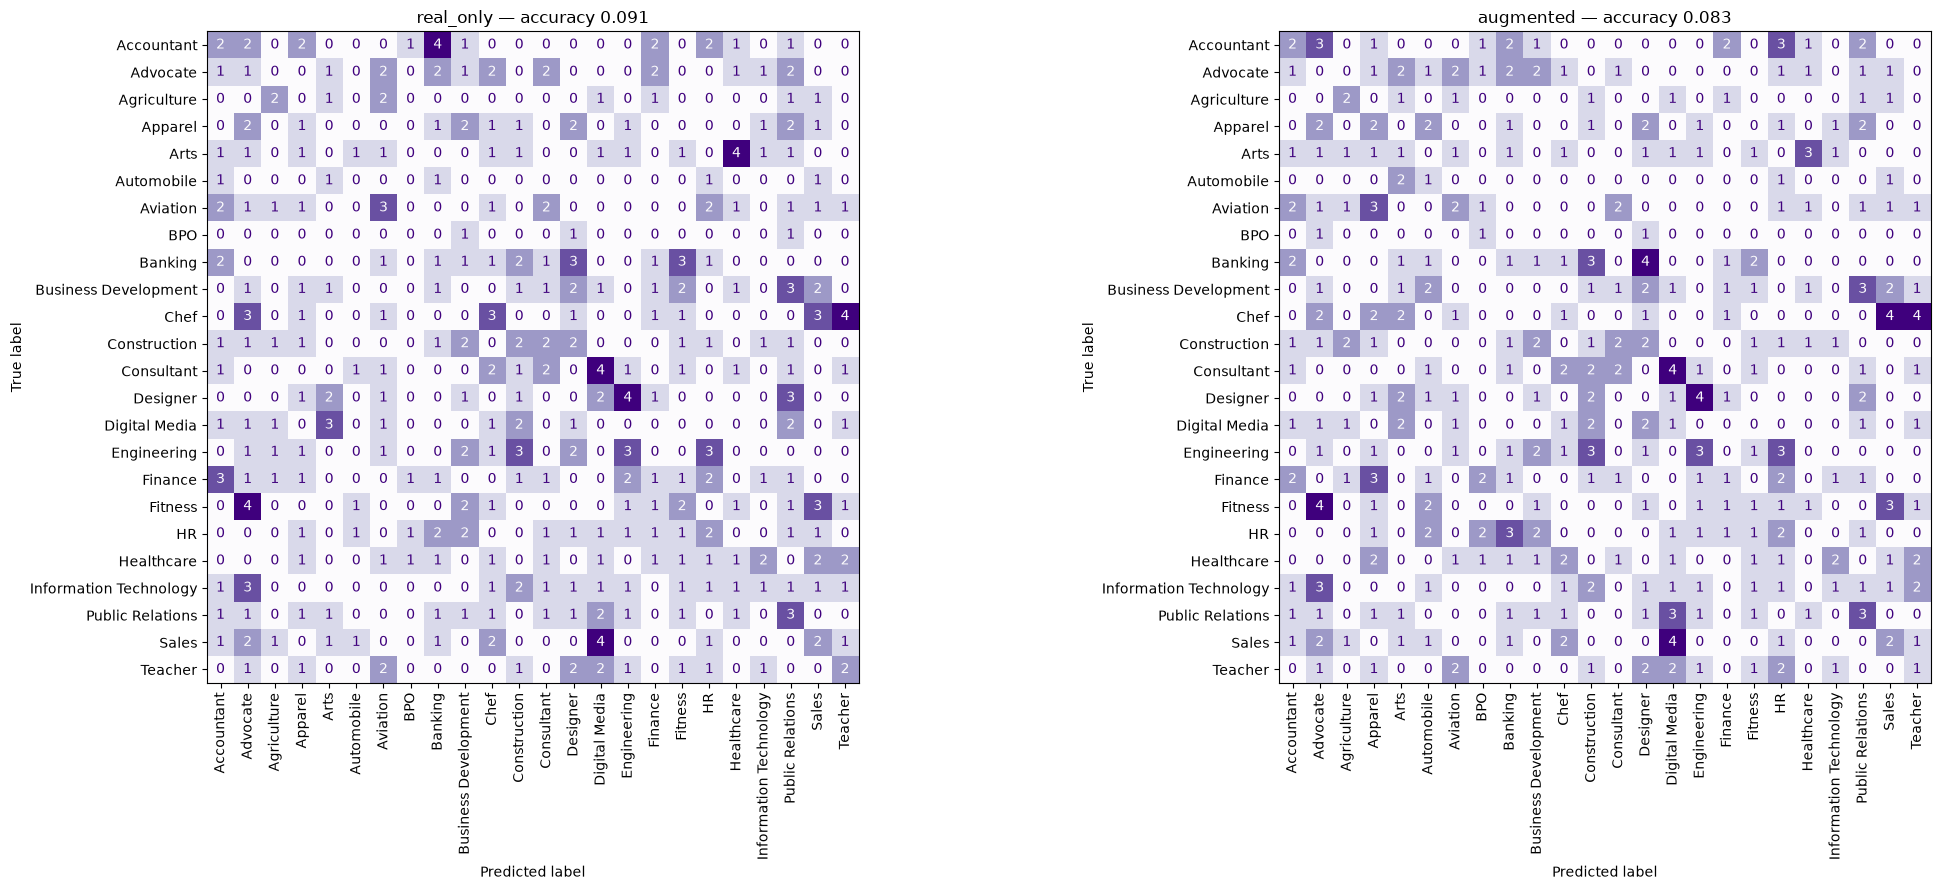

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

detail = results["detailed_test_report"]
for key in ("real_only", "augmented"):
    print(f"===== {key} (test split, seed {detail['seed']}) =====")
    print(detail[key]["classification_report_text"])

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
for a, key in zip(ax, ("real_only", "augmented")):
    ConfusionMatrixDisplay(np.array(detail[key]["confusion_matrix"]), display_labels=role_names).plot(
        ax=a, xticks_rotation=90, cmap="Purples", colorbar=False)
    a.set_title(f"{key} — accuracy {detail[key]['accuracy']:.3f}")
plt.tight_layout(); plt.show()

In [16]:
pd.DataFrame({name: {k: f"{v['mean']:.4f} ± {v['std']:.4f}" for k, v in s.items()} for name, s in
              {"real train (TRTR)": aug["real_only"]["test"], **{f"{n} synthetic only (TSTR)": v for n, v in results["tstr"].items()}}.items()}).T

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
real train (TRTR),0.0895 ± 0.0065,0.0911 ± 0.0076,0.0854 ± 0.0059,0.0865 ± 0.0064,0.0902 ± 0.0069
GAN synthetic only (TSTR),0.0745 ± 0.0134,0.0635 ± 0.0144,0.0683 ± 0.0123,0.0625 ± 0.0126,0.0685 ± 0.0139
CVAE baseline synthetic only (TSTR),0.0745 ± 0.0031,0.0458 ± 0.0109,0.0666 ± 0.0025,0.0405 ± 0.0028,0.0456 ± 0.0031


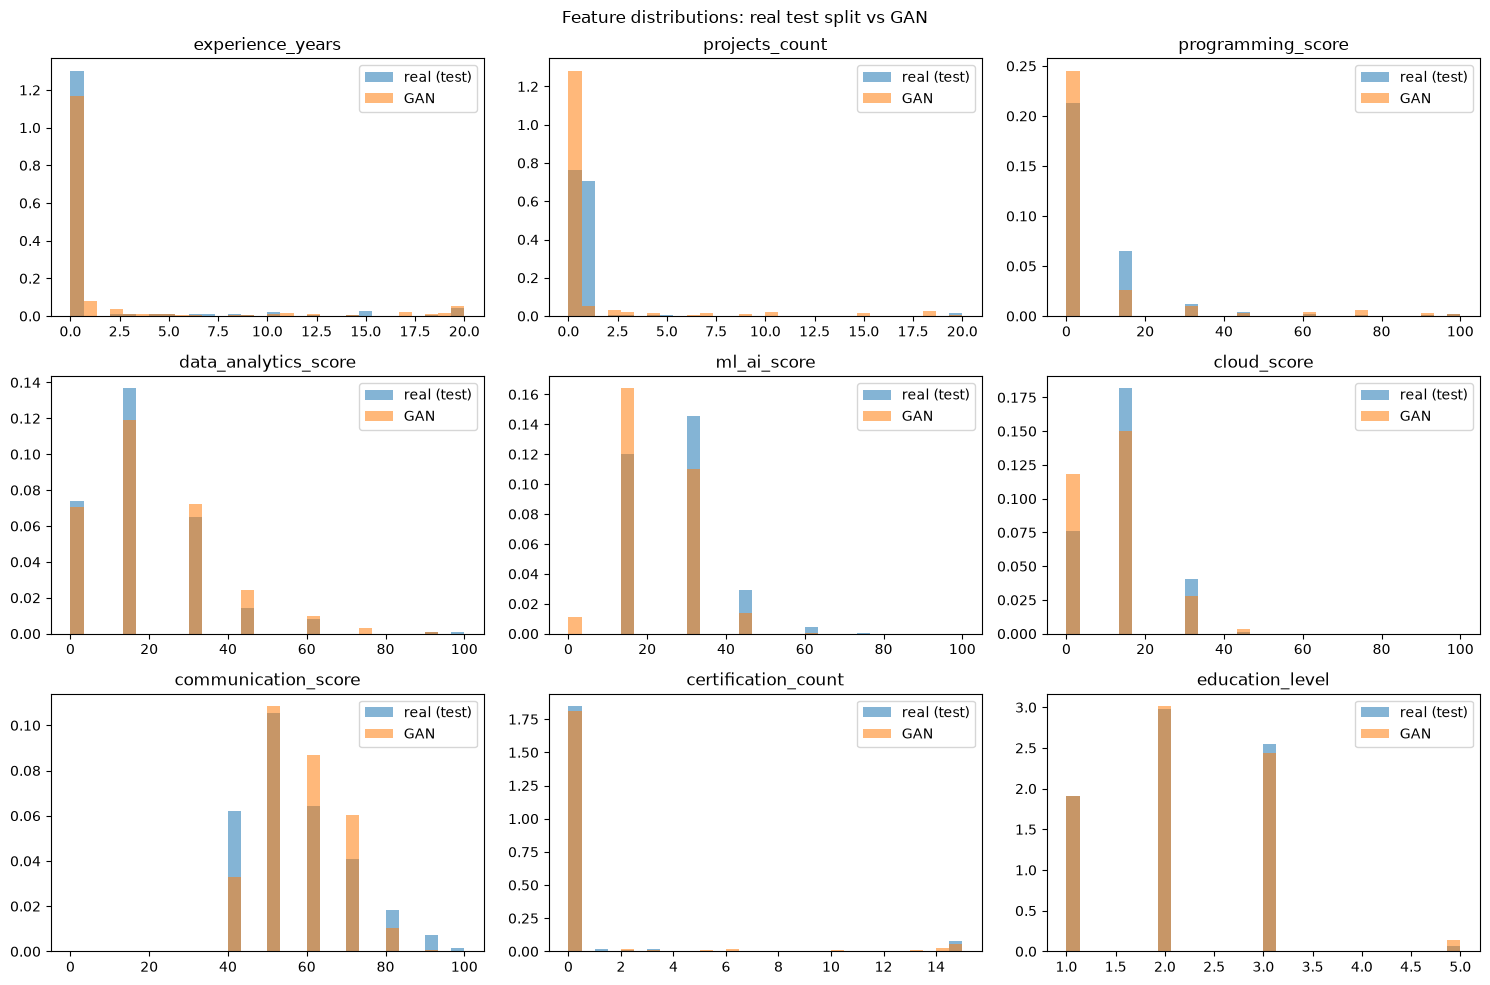

In [17]:
counts = test["job_role"].value_counts().to_dict()
gan_values, _ = model.generate_array(counts, seed=SEED)
fig, ax = plt.subplots(3, 3, figsize=(15, 10))
for j, (a, f) in enumerate(zip(ax.flat, ds.FEATURE_NAMES)):
    bins = np.linspace(*ds.FEATURE_BOUNDS[f], 31)
    a.hist(test[f], bins=bins, alpha=0.55, density=True, label="real (test)")
    a.hist(gan_values[:, j], bins=bins, alpha=0.55, density=True, label="GAN")
    a.set_title(f); a.legend()
plt.suptitle("Feature distributions: real test split vs GAN"); plt.tight_layout(); plt.show()

## 10. Export `metrics.json` and install into the app

In [18]:
metrics = build_metrics(report, role_names, config, history, check, results, QUICK_RUN, time.time() - start)
write_metrics(metrics, OUTPUT_DIR)
if EXPORT_TO_APP:
    for name in ("generator.safetensors", "discriminator.safetensors", "config.json", "metrics.json"):
        shutil.copy(os.path.join(OUTPUT_DIR, name), os.path.join(MODEL_DIR, name))
    print("Installed into", MODEL_DIR)
print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

Installed into D:\RecruitGen_Final\RecruitGen\models\gan
Saved: ['config.json', 'discriminator.safetensors', 'generator.safetensors', 'metrics.json']


## 11. Limitations

* The 9 features come from a keyword/regex extractor built for tech resumes. On the 24 mostly non-tech Kaggle
  categories they carry little signal (e.g. most resumes state no "N years of experience" phrase → experience 0), so the
  downstream classifier is weak for **real and augmented data alike** — read the deltas, not the absolute numbers.
* Short substring keywords in the extractor (`ai`, `ml`, `rag`, `s3`, …) also match ordinary words, which inflates some
  scores. The extractor is shared with Transformer V3 and was left unchanged.
* Generated profiles are synthetic feature vectors, not resumes; they must never be presented as real candidates.

## Final Evaluation — Classification performance + Confusion matrix

* **Accuracy** — overall correctness
* **Precision** — prediction reliability (macro average)
* **Recall** — role detection coverage (macro average)
* **F1-score** — precision-recall balance (macro average)

Downstream job-role classifier (24 roles) on the untouched real test split, mean over 5 seeds. Absolute scores are low for every row because the keyword extractor carries little signal on the non-tech Kaggle categories — read the differences between rows.

In [19]:
import pandas as pd

final_matrix = pd.DataFrame(
    {'training data': ['real only', 'real + GAN', 'real + CVAE baseline', 'real + Random oversampling'], 'Accuracy': [0.0895, 0.0815, 0.081, 0.0847], 'Precision': [0.0911, 0.0851, 0.0859, 0.086], 'Recall': [0.0854, 0.0819, 0.0772, 0.0804], 'F1-score': [0.0865, 0.0807, 0.0795, 0.0813]}
).set_index('training data')
final_matrix

,Accuracy,Precision,Recall,F1-score
training data,,,,
real only,0.0895,0.0911,0.0854,0.0865
real + GAN,0.0815,0.0851,0.0819,0.0807
real + CVAE baseline,0.0810,0.0859,0.0772,0.0795
real + Random oversampling,0.0847,0.0860,0.0804,0.0813


### Confusion matrix — real-only vs GAN-augmented training (test split)

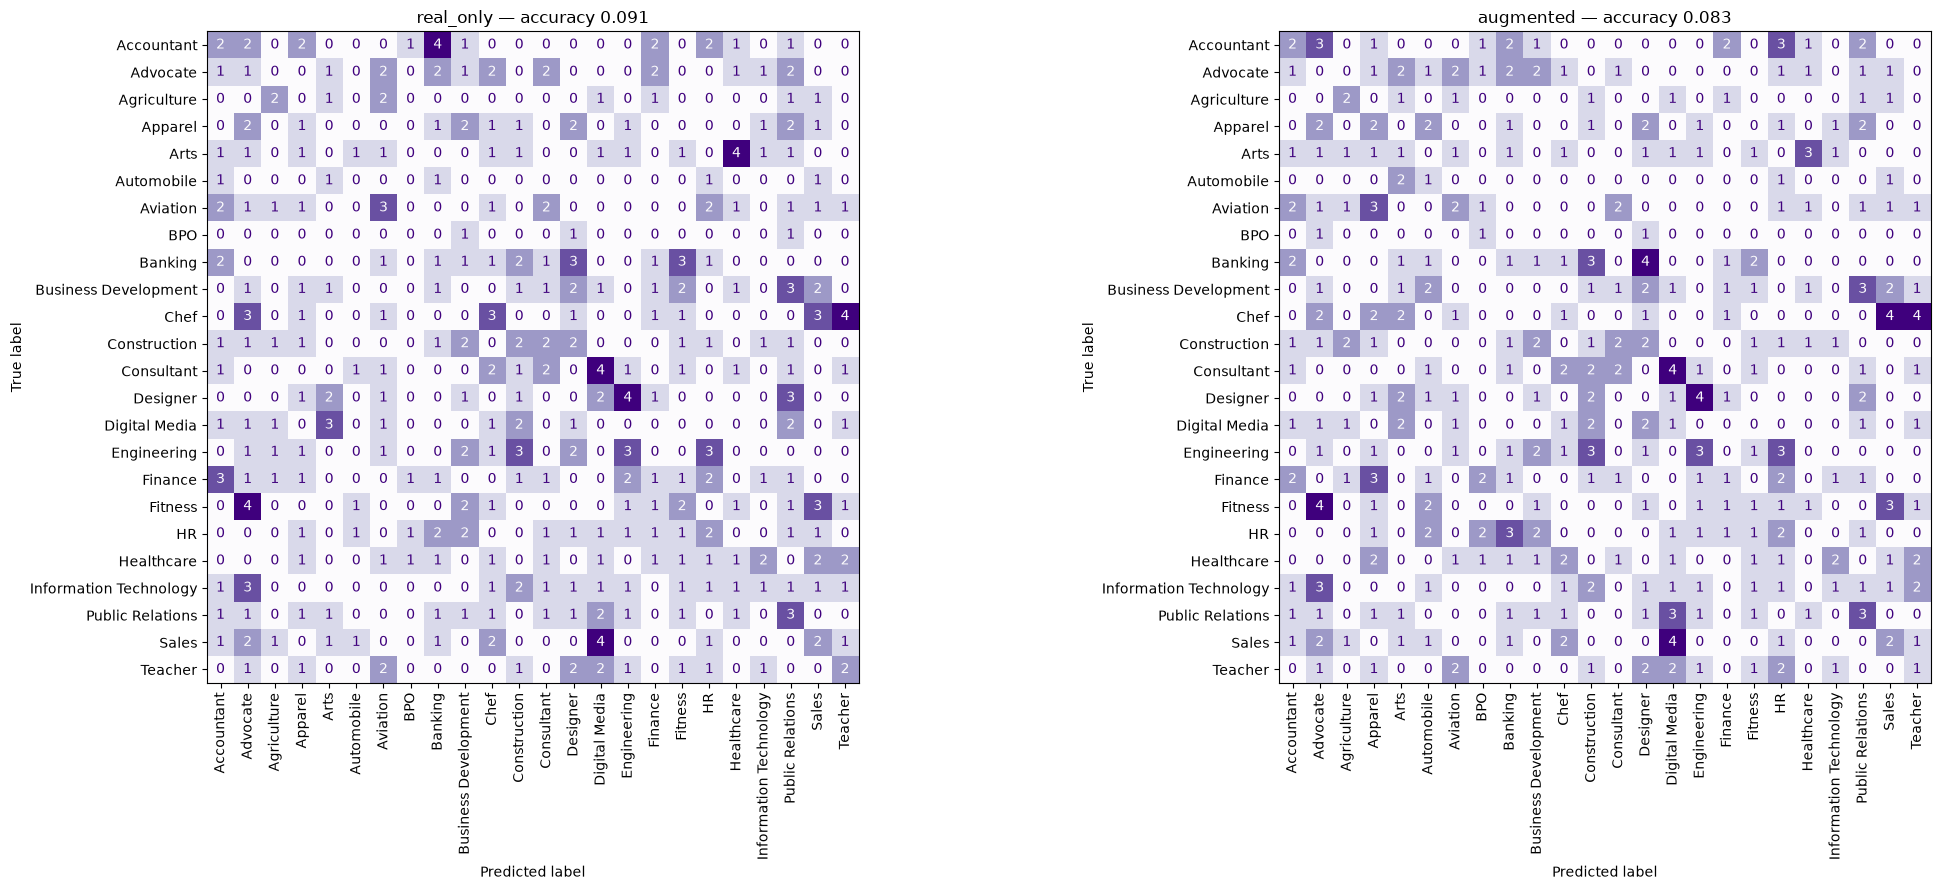